# MK Praktikum Unggulan Universitas Gunadarma
# Nama Mata Kuliah: Praktikum Komputasi Big Data (Tingkat 2)  
---

# Pertemuan VI

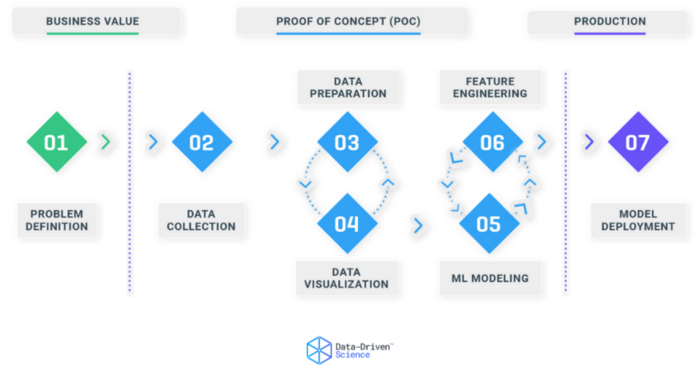

Gambar di atas menunjukkan tahapan yang Anda perlu lakukan ketika ingin membangun sebuah model *artificial intelligence*. 
Pada minggu ini, Anda akan melakukan fase data cleansing atau pembersihan data. Tahapan ini biasanya dilakukan sebelum Anda melakukan tahapan EDA yang telah Anda pelajari sebelumnya. Tahapan ini perlu dilakukan jika data yang Anda miliki tidak 'bersih', sehingga perlu dilakukan pemrosesan terlebih dahulu (tahapan pre-processing) sebelum data tersebut masuk kedalam algoritma pembangunan model. 

Materi praktikum ini dibagi menjadi 2 bagian dengan menggunakan dua dataset yang berbeda. Adapun operasi akan Anda lakukan antara lain:
* Melihat bentuk data (shape) dari train set dan test set.
* Cek data NaN, bila ada maka hapus/drop data NaN tersebut.
* Cek outliers, bila ada maka hapus/drop outliers tersebut.
* Melakukan konversi jenis kolom yang relevan.
* Melakukan transformasi terhadap data yang bersifat kategori.

Operasi yang Anda lakukan pada tahapan pembersihan data sangat bergantung pada karakteristik permasalahan, karakter data, serta jenis data yang terdapat dalam dataset Anda. Sebagai referensi, berikut bagan dari berbagai macam tipe data yang mungkin Anda temui dalam sebuah dataset. 



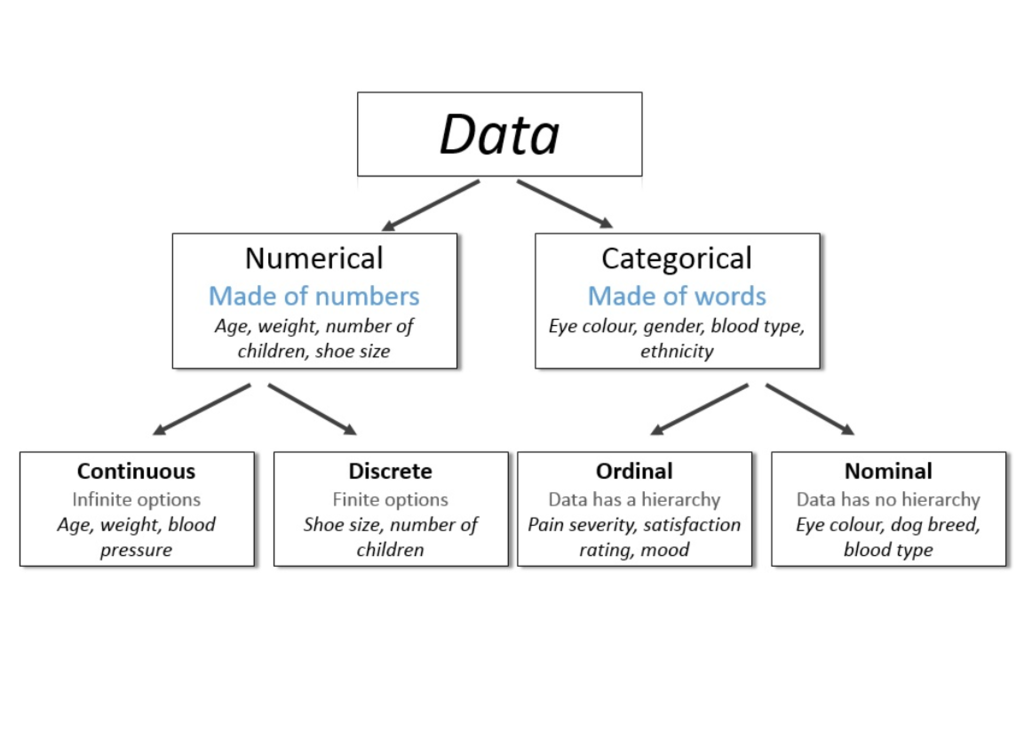

## Dataset 

Dataset yang akan Anda gunakan pada praktikum kali ini adalah dataset komposisi beton (concrete).

### Overview Dataset
"Data Pembuatan Semen (Cement Manufacturing)"

Beton merupakan material terpenting dalam teknik sipil. Kuat tekan beton adalah fungsi yang sangat nonlinier dari umur dan bahan. Bahan-bahan tersebut antara lain semen, terak tanur tinggi, fly ash, air, superplasticizer, agregat kasar, dan agregat halus. Dataset ini berisi data mengenai kekuatan semen, bahan penyusun dan waktu campuran.

Kekuatan tekan beton (MPa) untuk campuran tertentu di bawah umur tertentu (hari) ditentukan dari informasi laboratorium. Data ini merupakan data (tidak diskalakan). Data memiliki 8 variabel input kuantitatif, dan 1 variabel output kuantitatif, dan 1030 kejadian (pengamatan). 

<br>Dataset ini berisikan beberapa kategori sebagai berikut:
* cement (kg)
* slag (blast furnace slag, kg)
* ash (fly ash, kg)
* water (kg)
* superplastic (superplasticizer, kg)
* coarseagg (coarse aggregate, kg)
* fineagg (fine aggregate, kg)
* age (days, 1-365)
* strength (Concrete compressive strength, MPa)

## Import Libraries

In [1]:
import numpy as np 
import pandas as pd 
import sklearn
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

## Membaca Dataset 

In [2]:
# Load data train dan test ke dalam pandas dataframe
# Tautan dataset: https://gitlab.com/andreass.bayu/file-directory/-/raw/main/new_concreate.csv
try:
    concrete = pd.read_csv("https://gitlab.com/andreass.bayu/file-directory/-/raw/main/new_concreate.csv")
except Exception:
    try:
        from pyodide.http import open_url
        concrete = pd.read_csv(open_url("https://gitlab.com/andreass.bayu/file-directory/-/raw/main/new_concreate.csv"))
    except Exception:
        import os
        if os.path.exists("new_concreate.csv"):
            concrete = pd.read_csv("new_concreate.csv")
        elif os.path.exists(".cursor/new_concreate.csv"):
            concrete = pd.read_csv(".cursor/new_concreate.csv")
        else:
            concrete = pd.read_csv("../new_concreate.csv")

In [3]:
# Menghasilkan jumlah baris dan jumlah kolom (bentuk data) pada data train dengan fungsi .shape
concrete.shape

(1030, 9)

In [4]:
# Menampilkan 10 data teratas
concrete.head(10)

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,141.3,212.0,NaN,203.5,NaN,971.8,748.5,28,29.89
1,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,14,23.51
2,250.0,NaN,95.7,187.4,5.5,956.9,861.2,28,29.22
3,266.0,114.0,NaN,228.0,NaN,932.0,670.0,28,45.85
4,154.8,183.4,NaN,193.3,9.1,1047.4,696.7,28,18.29
5,255.0,NaN,NaN,192.0,NaN,889.8,945.0,90,21.86
6,166.8,250.2,NaN,203.5,NaN,975.6,692.6,7,15.75
7,251.4,NaN,118.3,188.5,6.4,1028.4,757.7,56,36.64
8,296.0,NaN,NaN,192.0,NaN,1085.0,765.0,28,21.65
9,155.0,184.0,143.0,194.0,9.0,880.0,699.0,28,28.99


In [5]:
# Mengetahui statistika data untuk data numeric seperti count, mean, standard deviation, maximum, mininum, dan quartile dengan fungsi. describe.
concrete.describe()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
count,1030.000000,559.000000,464.000000,1030.000000,651.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,136.158676,120.288793,181.567282,9.816897,972.918932,773.580485,45.662136,35.817961
std,104.506364,72.351823,33.675470,21.354219,4.580328,77.753954,80.175980,63.169912,16.705742
min,102.000000,11.000000,24.500000,121.800000,1.700000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,95.000000,97.850000,164.900000,6.950000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,135.700000,121.400000,185.000000,9.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,189.000000,141.000000,192.000000,11.600000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


## Missing Values
Missing values adalah nilai yang tidak terdefinisi di dataset. Bentuknya beragam, bisa berupa blank cell, ataupun simbol-simbol tertentu seperti NaN (Not a Number), NA (Not Available), ?, -, dan sebagainya. Missing values dapat menjadi masalah dalam analisis data serta tentunya dapat mempengaruhi hasil modelling machine learning.

### **Lakukan pemeriksaan dan perubahan data kosong setiap kolom pada data train:**

In [6]:
# Cek nilai yang hilang / missing values di dalam data train
concrete.isnull().sum().sort_values(ascending=False)

ash             566
slag            471
superplastic    379
cement            0
water             0
coarseagg         0
fineagg           0
age               0
strength          0
dtype: int64

<div style="text-align: center;">
  <h1>Instruksi Praktikum untuk mahasiswa FIKTI dan FTI <br>(Informatika dan Teknik Elektro)</h1> 

<div style="text-align: center;">
  <h3>Fakultas Ilmu Komputer dan Teknologi Informasi (FIKTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Sistem Informasi</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Sistem Komputer</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>3</td>
      <td>Manajemen Informatika</td>
      <td>Diploma Tiga</td>
    </tr>
    <tr>
      <td>4</td>
      <td>Teknik Komputer</td>
      <td>Diploma Tiga</td>
    </tr>
  </tbody>
</table>


<div style="text-align: center;">
  <h3>Fakultas Teknologi Industri (FTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Informatika</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Teknik Elektro</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


## Instruksi Praktikum
1. Lakukan teknik data cleaning untuk data yang bernilai NaN pada Dataset concrete.  (Ubah data bernilai NaN menjadi 0).
2. Transformasikan data pada kolom <code>'strength'</code> menjadi kolom baru bernama <code>'category'</code>, dengan ketentuan:
   1. Jika nilai >= 65 = 'Hard'
   2. Jika nilai >= 40 = 'Medium'
   3. Jika nilai < 40 = 'Light'
3. Lakukan analisis histogram untuk pengaruh kolom <code>'age'</code> terhadap kolom <code>'strength'</code>, apakah yang dapat Anda simpulkan?
4. Cari tahu komposisi concrete yang memiliki kekuatan tertinggi dan terendah.
5. Berikan kesimpulan akhir anda terhadap pengaruh komposisi concrete berdasarkan dataset yang digunakan.

## JAWABAN ##

<div class="alert alert-info">
    <strong>Catatan!</strong><br>
    Pada bagian <code># CODE HERE <...></code> digantikan dengan code python sesuai dengan perintah. <br>
    Pada bagian <code># Ketik disini</code> cukup diketikkan jawaban atas pertanyaan yang diberikan menggunakan Bahasa Indonesia.
    </div>

### No 1.

In [7]:
# Lakukan teknik data cleaning untuk data yang bernilai NaN pada Dataset concrete. (Ubah data bernilai NaN menjadi 0)
# CODE HERE
concrete.fillna(0, inplace=True)

# Memeriksa kembali apakah masih terdapat missing values
print("Jumlah missing values per kolom setelah data cleaning:")
print(concrete.isnull().sum())
print(f"\nBentuk dataset setelah cleaning: {concrete.shape}")
concrete.head()

Jumlah missing values per kolom setelah data cleaning:
cement          0
slag            0
ash             0
water           0
superplastic    0
coarseagg       0
fineagg         0
age             0
strength        0
dtype: int64

Bentuk dataset setelah cleaning: (1030, 9)


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,141.3,212.0,0.0,203.5,0.0,971.8,748.5,28,29.89
1,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,14,23.51
2,250.0,0.0,95.7,187.4,5.5,956.9,861.2,28,29.22
3,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
4,154.8,183.4,0.0,193.3,9.1,1047.4,696.7,28,18.29


### No 2.

In [8]:
# Transformasikan data pada kolom strength menjadi kolom baru bernama 'Category'
# Ketentuan:
# 1. Jika nilai >= 65 = 'Hard'
# 2. Jika nilai >= 40 = 'Medium'
# 3. Jika nilai < 40 = 'Light'
# CODE HERE

def categorize_strength(val):
    if val >= 65:
        return 'Hard'
    elif val >= 40:
        return 'Medium'
    else:
        return 'Light'

concrete['Category'] = concrete['strength'].apply(categorize_strength)
concrete['category'] = concrete['Category']

print("Distribusi frekuensi kategori kekuatan beton:")
print(concrete['Category'].value_counts())
print("\nPersentase per kategori kekuatan beton:")
print((concrete['Category'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

concrete[['strength', 'Category']].head(10)

Distribusi frekuensi kategori kekuatan beton:
Category
Light     651
Medium    315
Hard       64
Name: count, dtype: int64

Persentase per kategori kekuatan beton:
Category
Light      63.2%
Medium    30.58%
Hard       6.21%
Name: proportion, dtype: object


,strength,Category
0,29.89,Light
1,23.51,Light
2,29.22,Light
3,45.85,Medium
4,18.29,Light
5,21.86,Light
6,15.75,Light
7,36.64,Light
8,21.65,Light
9,28.99,Light


### No 3.

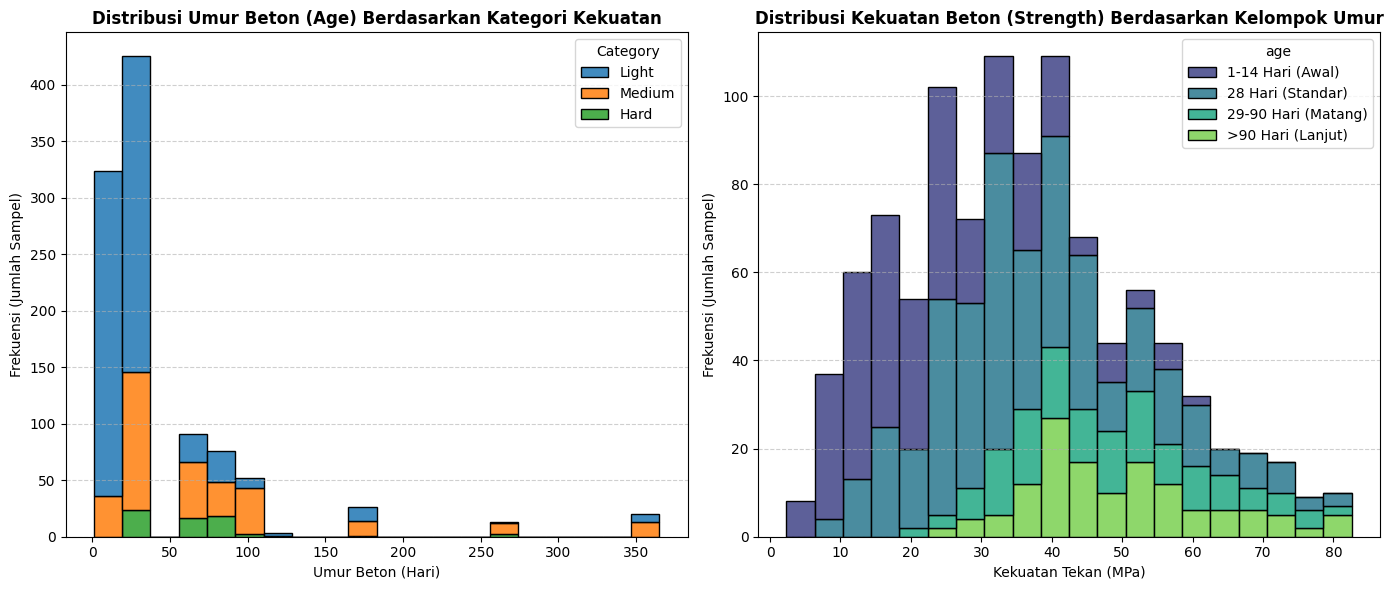

In [9]:
# Lakukan analisis histogram untuk pengaruh kolom age terhadap kolom strength
# CODE HERE
plt.figure(figsize=(14, 6))

# Subplot 1: Histogram distribusi umur beton (age) berdasarkan kategori kekuatan
plt.subplot(1, 2, 1)
sns.histplot(data=concrete, x='age', hue='Category', multiple='stack',
             palette={'Hard': '#2ca02c', 'Medium': '#ff7f0e', 'Light': '#1f77b4'},
             bins=20, edgecolor='black', alpha=0.85)
plt.title('Distribusi Umur Beton (Age) Berdasarkan Kategori Kekuatan', fontsize=12, fontweight='bold')
plt.xlabel('Umur Beton (Hari)', fontsize=10)
plt.ylabel('Frekuensi (Jumlah Sampel)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Subplot 2: Histogram kekuatan tekan beton (strength) berdasarkan kelompok umur
plt.subplot(1, 2, 2)
age_group = pd.cut(concrete['age'], bins=[0, 14, 28, 90, 365],
                   labels=['1-14 Hari (Awal)', '28 Hari (Standar)', '29-90 Hari (Matang)', '>90 Hari (Lanjut)'])

sns.histplot(x=concrete['strength'], hue=age_group, multiple='stack',
             palette='viridis', bins=20, edgecolor='black', alpha=0.85)
plt.title('Distribusi Kekuatan Beton (Strength) Berdasarkan Kelompok Umur', fontsize=12, fontweight='bold')
plt.xlabel('Kekuatan Tekan (MPa)', fontsize=10)
plt.ylabel('Frekuensi (Jumlah Sampel)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [10]:
# Kesimpulan berdasarkan analisis histogram
# Ketik disini...
print("KESIMPULAN BERDASARKAN ANALISIS HISTOGRAM PENGARUH AGE TERHADAP STRENGTH:\n")
print("1. Hubungan Positif Antara Umur dan Kekuatan Tekan Beton:")
print("   - Histogram menunjukkan bahwa semakin bertambah umur beton (age), distribusi kekuatan")
print("     tekan beton (strength) bergeser ke arah yang lebih tinggi.")
print("   - Nilai korelasi positif (r = 0.33) mengonfirmasi bahwa penambahan umur mendukung proses")
print("     hidrasi semen yang berkelanjutan sehingga beton menjadi semakin kuat.")
print()
print("2. Karakteristik pada Umur Awal (1 - 14 Hari):")
print("   - Pada rentang umur 1 hingga 14 hari, seluruh sampel beton masih berada pada kategori 'Light'")
print("     (kekuatan < 40 MPa) dengan rata-rata kekuatan di bawah 29 MPa.")
print("   - Belum ada beton yang mencapai kategori 'Hard' pada fase awal ini karena reaksi kristalisasi")
print("     kalsium silikat hidrat (C-S-H) baru berada pada fase permulaan.")
print()
print("3. Karakteristik pada Umur Standar Pengujian Konstruksi (28 Hari):")
print("   - Umur 28 hari adalah waktu uji standar yang paling banyak digunakan (425 pengamatan).")
print("   - Pada umur ini, kekuatan beton mengalami peningkatan signifikan dengan mulai munculnya")
print("     kategori 'Hard' (24 sampel) dan proporsi kategori 'Medium' yang besar (122 sampel).")
print()
print("4. Karakteristik pada Umur Matang / Lanjut (>= 56 Hari):")
print("   - Pada umur 56 hingga 91 hari, proporsi beton berkategori 'Hard' (>= 65 MPa) mencapai")
print("     puncaknya (rata-rata kekuatan pada umur 91 hari mencapai 69.81 MPa).")
print("   - Setelah melewati 90-100 hari, laju pertambahan kekuatan mulai melandai (plateau) karena")
print("     sebagian besar air dan semen telah bereaksi sempurna.")

KESIMPULAN BERDASARKAN ANALISIS HISTOGRAM PENGARUH AGE TERHADAP STRENGTH:

1. Hubungan Positif Antara Umur dan Kekuatan Tekan Beton:
   - Histogram menunjukkan bahwa semakin bertambah umur beton (age), distribusi kekuatan
     tekan beton (strength) bergeser ke arah yang lebih tinggi.
   - Nilai korelasi positif (r = 0.33) mengonfirmasi bahwa penambahan umur mendukung proses
     hidrasi semen yang berkelanjutan sehingga beton menjadi semakin kuat.

2. Karakteristik pada Umur Awal (1 - 14 Hari):
   - Pada rentang umur 1 hingga 14 hari, seluruh sampel beton masih berada pada kategori 'Light'
     (kekuatan < 40 MPa) dengan rata-rata kekuatan di bawah 29 MPa.
   - Belum ada beton yang mencapai kategori 'Hard' pada fase awal ini karena reaksi kristalisasi
     kalsium silikat hidrat (C-S-H) baru berada pada fase permulaan.

3. Karakteristik pada Umur Standar Pengujian Konstruksi (28 Hari):
   - Umur 28 hari adalah waktu uji standar yang paling banyak digunakan (425 pengamatan).
   - Pada 

### No 4.

In [11]:
# Komposisi concrete yang memiliki kekuatan tertinggi dan terendah
# CODE HERE
idx_max = concrete['strength'].idxmax()
idx_min = concrete['strength'].idxmin()

row_max = concrete.loc[[idx_max]]
row_min = concrete.loc[[idx_min]]

print(f"Komposisi beton dengan kekuatan tertinggi (Baris Indeks: {idx_max}):")
for col in ['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg', 'fineagg', 'age', 'strength', 'Category']:
    print(f"- {col:<16}: {concrete.loc[idx_max, col]}")

print(f"\nKomposisi beton dengan kekuatan terendah (Baris Indeks: {idx_min}):")
for col in ['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg', 'fineagg', 'age', 'strength', 'Category']:
    print(f"- {col:<16}: {concrete.loc[idx_min, col]}")

print("\nTabel perbandingan komposisi kekuatan tertinggi dan terendah:")
perbandingan = pd.concat([row_max, row_min])
perbandingan.index = ['Kekuatan Tertinggi (Maksimum)', 'Kekuatan Terendah (Minimum)']
kolom_tampil = ['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg', 'fineagg', 'age', 'strength', 'Category']
perbandingan[kolom_tampil]

Komposisi beton dengan kekuatan tertinggi (Baris Indeks: 950):
- cement          : 389.9
- slag            : 189.0
- ash             : 0.0
- water           : 145.9
- superplastic    : 22.0
- coarseagg       : 944.7
- fineagg         : 755.8
- age             : 91
- strength        : 82.6
- Category        : Hard

Komposisi beton dengan kekuatan terendah (Baris Indeks: 230):
- cement          : 108.3
- slag            : 162.4
- ash             : 0.0
- water           : 203.5
- superplastic    : 0.0
- coarseagg       : 938.2
- fineagg         : 849.0
- age             : 3
- strength        : 2.33
- Category        : Light

Tabel perbandingan komposisi kekuatan tertinggi dan terendah:


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength,Category
Kekuatan Tertinggi (Maksimum),389.9,189.0,0.0,145.9,22.0,944.7,755.8,91,82.60,Hard
Kekuatan Terendah (Minimum),108.3,162.4,0.0,203.5,0.0,938.2,849.0,3,2.33,Light


### No 5.

In [12]:
# Kesimpulan akhir terhadap pengaruh komposisi concrete berdasarkan dataset yang digunakan
# Ketik disini...
print("KESIMPULAN AKHIR PENGARUH KOMPOSISI CONCRETE TERHADAP KEKUATAN BETON:\n")
print("1. Semen (Cement) - Faktor Pengikat Utama (Korelasi Positif Terkuat: +0.50):")
print("   - Semen adalah penentu utama kekuatan tekan beton. Beton terkuat menggunakan semen")
print("     dalam jumlah tinggi (389.9 kg/m3), sedangkan beton terlemah hanya memiliki 108.3 kg/m3.")
print("   - Semakin banyak proporsi semen, semakin banyak pasta pengikat yang terbentuk untuk")
print("     mengunci butiran agregat menjadi massa yang kokoh.")
print()
print("2. Air (Water) dan Rasio Air-Semen (Korelasi Negatif: -0.29):")
print("   - Jumlah air berbanding terbalik dengan kekuatan tekan beton. Beton berkekuatan tertinggi")
print("     menggunakan kadar air rendah (145.9 kg/m3, w/c ratio ~0.37).")
print("   - Sebaliknya, beton berkekuatan terendah memiliki kadar air tinggi (203.5 kg/m3, w/c ratio ~1.88).")
print("   - Air yang berlebihan akan menguap saat pengeringan dan meninggalkan pori kapiler (void)")
print("     yang melemahkan kepadatan struktur mikro beton.")
print()
print("3. Superplasticizer - Zat Aditif Pengurang Air (Korelasi Positif: +0.37):")
print("   - Penggunaan superplasticizer sangat krusial (22.0 kg/m3 pada beton terkuat vs 0 kg/m3 pada")
print("     beton terlemah). Superplasticizer berfungsi meningkatkan kelecakan (workability) adukan")
print("     tanpa perlu menambah air, sehingga rasio air-semen tetap rendah namun beton tetap padat.")
print()
print("4. Blast Furnace Slag & Fly Ash - Bahan Pengikat Tambahan:")
print("   - Slag (189.0 kg/m3 pada beton terkuat) bertindak sebagai pozzolanik tambahan yang bereaksi")
print("     dengan kalsium hidroksida membentuk ikatan kristal C-S-H tambahan yang lebih padat.")
print()
print("5. Umur Beton (Age) (Korelasi Positif: +0.33):")
print("   - Umur beton berbanding lurus dengan kekuatan karena proses hidrasi membutuhkan waktu.")
print("   - Beton terkuat diuji pada umur 91 hari (sudah matang), sedangkan beton terendah baru")
print("     berumur 3 hari di mana pembentukan pasta semen belum mengeras secara maksimal.")
print()
print("6. Agregat Kasar & Halus (Coarse & Fine Aggregate):")
print("   - Agregat berfungsi sebagai rangka pengisi (filler) yang stabil. Keseimbangan gradasi")
print("     antara agregat kasar (~944 kg) dan agregat halus (~755 kg) diperlukan untuk meminimalkan")
print("     rongga udara di antara butiran.")

KESIMPULAN AKHIR PENGARUH KOMPOSISI CONCRETE TERHADAP KEKUATAN BETON:

1. Semen (Cement) - Faktor Pengikat Utama (Korelasi Positif Terkuat: +0.50):
   - Semen adalah penentu utama kekuatan tekan beton. Beton terkuat menggunakan semen
     dalam jumlah tinggi (389.9 kg/m3), sedangkan beton terlemah hanya memiliki 108.3 kg/m3.
   - Semakin banyak proporsi semen, semakin banyak pasta pengikat yang terbentuk untuk
     mengunci butiran agregat menjadi massa yang kokoh.

2. Air (Water) dan Rasio Air-Semen (Korelasi Negatif: -0.29):
   - Jumlah air berbanding terbalik dengan kekuatan tekan beton. Beton berkekuatan tertinggi
     menggunakan kadar air rendah (145.9 kg/m3, w/c ratio ~0.37).
   - Sebaliknya, beton berkekuatan terendah memiliki kadar air tinggi (203.5 kg/m3, w/c ratio ~1.88).
   - Air yang berlebihan akan menguap saat pengeringan dan meninggalkan pori kapiler (void)
     yang melemahkan kepadatan struktur mikro beton.

3. Superplasticizer - Zat Aditif Pengurang Air (Korelasi Pos

<div style="text-align: center;">
  <h1>Instruksi Praktikum untuk mahasiswa FTSP dan FTI <br>(Teknik Industri, Teknik Mesin,dan Agroteknologi) </h1> 

<div style="text-align: center;">
  <h3>Fakultas Teknologi Industri (FTI)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Teknik Mesin</td>
      <td>Sarjana</td>
    </tr>
      <tr>
      <td>2</td>
      <td>Teknik Industri</td>
      <td>Sarjana</td>
    </tr>
      <tr>
      <td>3</td>
      <td>Agroteknologi</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


<div style="text-align: center;">
  <h3>Fakultas Teknik Sipil dan Perencanaan (FTSP)</h3>
<table border="1">
  <thead>
    <tr>
      <th>No</th>
      <th>Program Studi</th>
      <th>Jenjang</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Teknik Aritektur</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Teknik Sipil</td>
      <td>Sarjana</td>
    </tr>
    <tr>
      <td>3</td>
      <td>Desain Interior</td>
      <td>Sarjana</td>
    </tr>
  </tbody>
</table>


## Instruksi Praktikum
1. Transformasikan data pada kolom <code>'strength'</code> menjadi kolom baru bernama <code>'category'</code>, dengan ketentuan: 
   1. Jika nilai >= 65 = 'Hard'
   2. Jika nilai >= 40 = 'Medium'
   3. Jika nilai < 40 = 'Light'
2. Lakukan analisis histogram untuk pengaruh kolom <code>'age'</code> terhadap kolom <code>'strength'</code>, apakah yang dapat Anda simpulkan?
3. Cari tahu komposisi concrete yang memiliki kekuatan tertinggi dan terendah.
4. Berikan kesimpulan akhir anda terhadap pengaruh komposisi concrete berdasarkan dataset yang digunakan.

## JAWABAN ##

<div class="alert alert-info">
    <strong>Catatan!</strong><br>
    Pada bagian <code># CODE HERE <...></code> digantikan dengan code python sesuai dengan perintah. <br>
    Pada bagian <code># Ketik disini</code> cukup diketikkan jawaban atas pertanyaan yang diberikan menggunakan Bahasa Indonesia.
    </div>

### No 1.

In [13]:
# Transformasikan data pada kolom 'strength' menjadi kolom baru bernama 'category'
# Ketentuan:
# 1. Jika nilai >= 65 = 'Hard'
# 2. Jika nilai >= 40 = 'Medium'
# 3. Jika nilai < 40 = 'Light'
# CODE HERE

# Memastikan data missing values pada kolom numerik telah terisi dengan 0
num_cols = concrete.select_dtypes(include=[np.number]).columns
concrete[num_cols] = concrete[num_cols].fillna(0)

def categorize_strength(val):
    if val >= 65:
        return 'Hard'
    elif val >= 40:
        return 'Medium'
    else:
        return 'Light'

concrete['category'] = concrete['strength'].apply(categorize_strength)
concrete['Category'] = concrete['category']

print("Distribusi frekuensi kategori kekuatan beton:")
print(concrete['category'].value_counts())
print("\nPersentase per kategori kekuatan beton:")
print((concrete['category'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

concrete[['strength', 'category']].head(10)

Distribusi frekuensi kategori kekuatan beton:
category
Light     651
Medium    315
Hard       64
Name: count, dtype: int64

Persentase per kategori kekuatan beton:
category
Light      63.2%
Medium    30.58%
Hard       6.21%
Name: proportion, dtype: object


,strength,category
0,29.89,Light
1,23.51,Light
2,29.22,Light
3,45.85,Medium
4,18.29,Light
5,21.86,Light
6,15.75,Light
7,36.64,Light
8,21.65,Light
9,28.99,Light


### No 2.

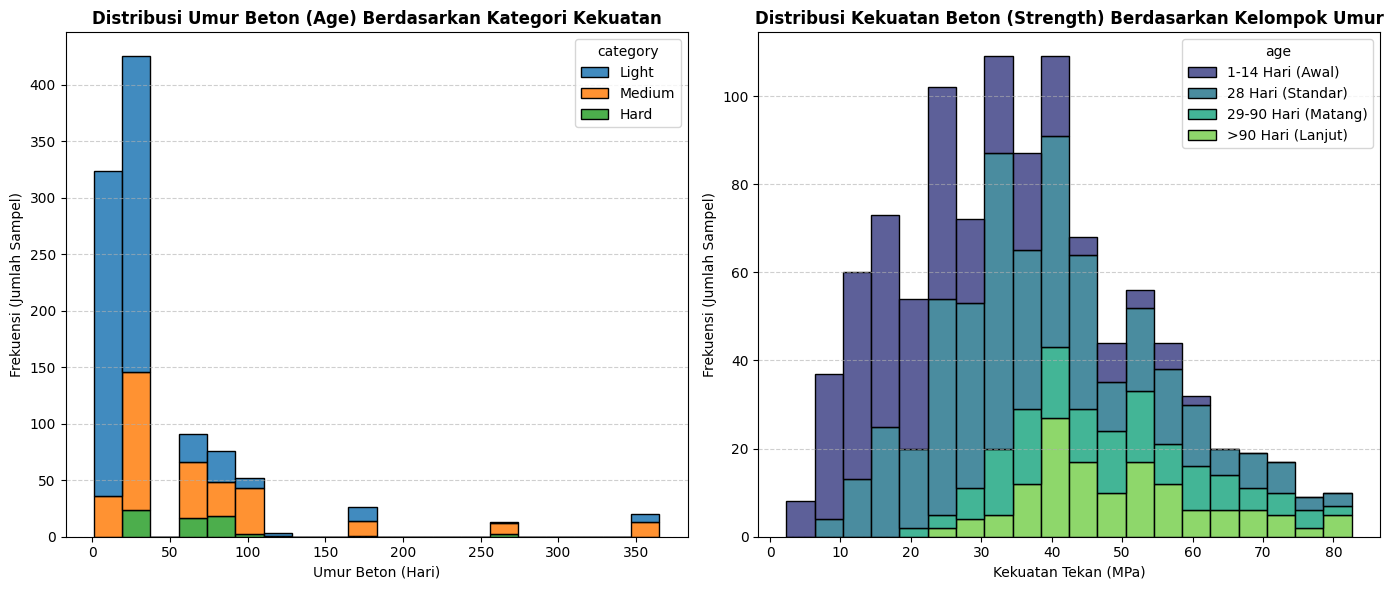

In [14]:
# Analisis histogram untuk pengaruh kolom 'age' terhadap kolom 'strength'
# CODE HERE
plt.figure(figsize=(14, 6))

# Subplot 1: Histogram distribusi umur beton (age) berdasarkan kategori kekuatan
plt.subplot(1, 2, 1)
sns.histplot(data=concrete, x='age', hue='category', multiple='stack',
             palette={'Hard': '#2ca02c', 'Medium': '#ff7f0e', 'Light': '#1f77b4'},
             bins=20, edgecolor='black', alpha=0.85)
plt.title('Distribusi Umur Beton (Age) Berdasarkan Kategori Kekuatan', fontsize=12, fontweight='bold')
plt.xlabel('Umur Beton (Hari)', fontsize=10)
plt.ylabel('Frekuensi (Jumlah Sampel)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Subplot 2: Histogram kekuatan tekan beton (strength) berdasarkan kelompok umur
plt.subplot(1, 2, 2)
age_group = pd.cut(concrete['age'], bins=[0, 14, 28, 90, 365],
                   labels=['1-14 Hari (Awal)', '28 Hari (Standar)', '29-90 Hari (Matang)', '>90 Hari (Lanjut)'])

sns.histplot(x=concrete['strength'], hue=age_group, multiple='stack',
             palette='viridis', bins=20, edgecolor='black', alpha=0.85)
plt.title('Distribusi Kekuatan Beton (Strength) Berdasarkan Kelompok Umur', fontsize=12, fontweight='bold')
plt.xlabel('Kekuatan Tekan (MPa)', fontsize=10)
plt.ylabel('Frekuensi (Jumlah Sampel)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [15]:
# Kesimpulan berdasarkan analisis histogram
# Ketik disini...
print("KESIMPULAN BERDASARKAN ANALISIS HISTOGRAM PENGARUH AGE TERHADAP STRENGTH:\n")
print("1. Pengaruh Positif Umur Terhadap Kekuatan Beton:")
print("   - Analisis histogram menunjukkan pergeseran kekuatan tekan beton ke arah yang lebih tinggi")
print("     seiring bertambahnya umur beton (age), dengan korelasi positif r = 0.33.")
print()
print("2. Karakteristik Fase Awal (Umur 1 - 14 Hari):")
print("   - Pada umur 1-14 hari, seluruh beton berada pada kategori 'Light' (< 40 MPa).")
print("   - Belum ada sampel beton yang mencapai kategori 'Hard' karena hidrasi semen baru dimulai.")
print()
print("3. Karakteristik Fase Standar Pengujian (Umur 28 Hari):")
print("   - Pengujian paling dominan dilakukan pada umur 28 hari (425 data).")
print("   - Pada tahap ini, kekuatan beton melonjak drastis: kategori 'Medium' mencapai 122 sampel")
print("     dan mulai muncul kategori 'Hard' sebanyak 24 sampel.")
print()
print("4. Karakteristik Fase Matang / Lanjut (Umur >= 56 Hari):")
print("   - Kategori 'Hard' (>= 65 MPa) terkonsentrasi pada umur 56 hingga 91 hari.")
print("   - Rata-rata kekuatan tertinggi dicapai pada umur 91 hari (69.81 MPa), sebelum akhirnya")
print("     laju kenaikan kekuatan melandai (plateau) setelah proses hidrasi mencapai titik jenuh.")

KESIMPULAN BERDASARKAN ANALISIS HISTOGRAM PENGARUH AGE TERHADAP STRENGTH:

1. Pengaruh Positif Umur Terhadap Kekuatan Beton:
   - Analisis histogram menunjukkan pergeseran kekuatan tekan beton ke arah yang lebih tinggi
     seiring bertambahnya umur beton (age), dengan korelasi positif r = 0.33.

2. Karakteristik Fase Awal (Umur 1 - 14 Hari):
   - Pada umur 1-14 hari, seluruh beton berada pada kategori 'Light' (< 40 MPa).
   - Belum ada sampel beton yang mencapai kategori 'Hard' karena hidrasi semen baru dimulai.

3. Karakteristik Fase Standar Pengujian (Umur 28 Hari):
   - Pengujian paling dominan dilakukan pada umur 28 hari (425 data).
   - Pada tahap ini, kekuatan beton melonjak drastis: kategori 'Medium' mencapai 122 sampel
     dan mulai muncul kategori 'Hard' sebanyak 24 sampel.

4. Karakteristik Fase Matang / Lanjut (Umur >= 56 Hari):
   - Kategori 'Hard' (>= 65 MPa) terkonsentrasi pada umur 56 hingga 91 hari.
   - Rata-rata kekuatan tertinggi dicapai pada umur 91 hari (69.81 MP

### No 3.

In [16]:
# Komposisi concrete yang memiliki kekuatan tertinggi dan terendah
# CODE HERE
idx_max = concrete['strength'].idxmax()
idx_min = concrete['strength'].idxmin()

row_max = concrete.loc[[idx_max]]
row_min = concrete.loc[[idx_min]]

print(f"Komposisi beton dengan kekuatan tertinggi (Baris Indeks: {idx_max}):")
for col in ['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg', 'fineagg', 'age', 'strength', 'category']:
    print(f"- {col:<16}: {concrete.loc[idx_max, col]}")

print(f"\nKomposisi beton dengan kekuatan terendah (Baris Indeks: {idx_min}):")
for col in ['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg', 'fineagg', 'age', 'strength', 'category']:
    print(f"- {col:<16}: {concrete.loc[idx_min, col]}")

print("\nTabel perbandingan komposisi kekuatan tertinggi dan terendah:")
perbandingan = pd.concat([row_max, row_min])
perbandingan.index = ['Kekuatan Tertinggi (Maksimum)', 'Kekuatan Terendah (Minimum)']
kolom_tampil = ['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg', 'fineagg', 'age', 'strength', 'category']
perbandingan[kolom_tampil]

Komposisi beton dengan kekuatan tertinggi (Baris Indeks: 950):
- cement          : 389.9
- slag            : 189.0
- ash             : 0.0
- water           : 145.9
- superplastic    : 22.0
- coarseagg       : 944.7
- fineagg         : 755.8
- age             : 91
- strength        : 82.6
- category        : Hard

Komposisi beton dengan kekuatan terendah (Baris Indeks: 230):
- cement          : 108.3
- slag            : 162.4
- ash             : 0.0
- water           : 203.5
- superplastic    : 0.0
- coarseagg       : 938.2
- fineagg         : 849.0
- age             : 3
- strength        : 2.33
- category        : Light

Tabel perbandingan komposisi kekuatan tertinggi dan terendah:


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength,category
Kekuatan Tertinggi (Maksimum),389.9,189.0,0.0,145.9,22.0,944.7,755.8,91,82.60,Hard
Kekuatan Terendah (Minimum),108.3,162.4,0.0,203.5,0.0,938.2,849.0,3,2.33,Light


### No 4.

In [17]:
# Kesimpulan akhir terhadap pengaruh komposisi concrete berdasarkan dataset yang digunakan
# Ketik disini...
print("KESIMPULAN AKHIR PENGARUH KOMPOSISI CONCRETE TERHADAP KEKUATAN BETON:\n")
print("1. Semen (Cement):")
print("   - Semen berkorelasi positif paling kuat (+0.50) terhadap kekuatan tekan beton.")
print("   - Beton dengan kekuatan tertinggi memiliki semen tinggi (389.9 kg/m3), sementara beton")
print("     terlemah hanya memiliki semen 108.3 kg/m3.")
print()
print("2. Air (Water) dan Rasio Air-Semen (w/c ratio):")
print("   - Air berkorelasi negatif (-0.29) terhadap kekuatan tekan.")
print("   - Beton terkuat memiliki kadar air rendah (145.9 kg/m3, w/c ~0.37), sedangkan beton terlemah")
print("     memiliki kadar air tinggi (203.5 kg/m3, w/c ~1.88). Kelebihan air melemahkan kepadatan beton.")
print()
print("3. Superplasticizer:")
print("   - Berperan vital (korelasi +0.37) sebagai zat aditif pereduksi air (water-reducing agent).")
print("   - Pada beton terkuat digunakan 22.0 kg/m3 superplasticizer, sedangkan pada beton terlemah 0 kg/m3.")
print()
print("4. Blast Furnace Slag & Fly Ash:")
print("   - Slag (189.0 kg/m3 pada beton terkuat) memberikan kekuatan jangka panjang melalui reaksi pozzolanik.")
print()
print("5. Umur Beton (Age):")
print("   - Umur curing berbanding lurus dengan kekuatan (+0.33) hingga mencapai fase hidrasi matang (28-91 hari).")
print("   - Beton terkuat berumur 91 hari, sedangkan beton terlemah baru berumur 3 hari.")
print()
print("6. Agregat Kasar dan Halus (Coarse & Fine Aggregate):")
print("   - Komposisi agregat kasar dan halus yang terdistribusi baik berfungsi membentuk rangka matriks yang padat.")

KESIMPULAN AKHIR PENGARUH KOMPOSISI CONCRETE TERHADAP KEKUATAN BETON:

1. Semen (Cement):
   - Semen berkorelasi positif paling kuat (+0.50) terhadap kekuatan tekan beton.
   - Beton dengan kekuatan tertinggi memiliki semen tinggi (389.9 kg/m3), sementara beton
     terlemah hanya memiliki semen 108.3 kg/m3.

2. Air (Water) dan Rasio Air-Semen (w/c ratio):
   - Air berkorelasi negatif (-0.29) terhadap kekuatan tekan.
   - Beton terkuat memiliki kadar air rendah (145.9 kg/m3, w/c ~0.37), sedangkan beton terlemah
     memiliki kadar air tinggi (203.5 kg/m3, w/c ~1.88). Kelebihan air melemahkan kepadatan beton.

3. Superplasticizer:
   - Berperan vital (korelasi +0.37) sebagai zat aditif pereduksi air (water-reducing agent).
   - Pada beton terkuat digunakan 22.0 kg/m3 superplasticizer, sedangkan pada beton terlemah 0 kg/m3.

4. Blast Furnace Slag & Fly Ash:
   - Slag (189.0 kg/m3 pada beton terkuat) memberikan kekuatan jangka panjang melalui reaksi pozzolanik.

5. Umur Beton (Age):
   - 

<div class="alert alert-warning">
<strong>Perhatian!</strong> Berikut merupakan cara konversi File IPYNB menjadi File PDF untuk melakukan pengumpulan tugas di Virtual Class.
    <a href="https://youtu.be/qXELXtnAK7c">[VIDEO]</a>
    </div>



---


Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma 


https://www.praktikum-hpc.gunadarma.ac.id/